# Submission 4: CNN with an Attention Module
**Project:** Pneumonia Detection from Chest X-Ray Images using Deep Learning  
**Roadmap Requirement:** Add one attention module (e.g., SE block) to the custom CNN from Submission 3, measure its impact, and provide a direct baseline comparison with full metrics, confusion matrix, and curves.

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dense, Dropout, GlobalAveragePooling2D, Reshape, Multiply
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Dataset configuration
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

DATA_DIR = os.path.join(path, "chest_xray", "chest_xray")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join(path, "chest_xray")

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VAL_DIR = os.path.join(DATA_DIR, 'val')
TEST_DIR = os.path.join(DATA_DIR, 'test')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Consistent data augmentation pipeline
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=False
)

100%|██████████| 2.29G/2.29G [00:20<00:00, 123MB/s]

Extracting files...


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
# Define Squeeze-and-Excitation (SE) Attention Module
def se_block(input_tensor, ratio=8):
    channels = input_tensor.shape[-1]
    x = GlobalAveragePooling2D()(input_tensor)
    x = Reshape((1, 1, channels))(x)
    x = Dense(channels // ratio, activation='relu', use_bias=False)(x)
    x = Dense(channels, activation='sigmoid', use_bias=False)(x)
    return Multiply()([input_tensor, x])

# Build Attention-Augmented Custom CNN (Adding SE Block after Block 2)
inputs = tf.keras.Input(shape=(224, 224, 3))

# Block 1
x = Conv2D(32, (3,3), activation='relu')(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D(2,2)(x)

# Block 2
x = Conv2D(64, (3,3), activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(2,2)(x)

# Insert Attention Module here (Changes nothing else from Sub 3 baseline structure)
x = se_block(x)

# Block 3
x = Conv2D(128, (3,3), activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(2,2)(x)

# Fully Connected Classification Head
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation='sigmoid')(x)

attention_cnn = Model(inputs, outputs, name="Attention_Custom_CNN")

attention_cnn.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

attention_cnn.summary()

Model: "Attention_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 222, 222,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 222, 222,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 111, 111,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 109, 109,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 54, 54,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 8)   │        512 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 64)  │        512 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 54, 54,    │          0 │ max_pooling2d_1[… │
│                     │ 64)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 52, 52,    │     73,856 │ multiply[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 26, 26,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 86528)     │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │ 22,151,424 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │        257 │ dropout[0][0]   

 Total params: 22,246,849 (84.86 MB)

 Trainable params: 22,246,401 (84.86 MB)

 Non-trainable params: 448 (1.75 KB)

In [4]:
# Training with Early Stopping (Consistent hyperparameters)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Starting Attention-Augmented CNN training...")
start_train_time = time.time()

history_attention = attention_cnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,
    callbacks=[early_stop],
    verbose=1
)

attn_train_time = time.time() - start_train_time
print(f"⏱️ Training Time: {attn_train_time:.2f} seconds")

Starting Attention-Augmented CNN training...
Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 638s 4s/step - accuracy: 0.9024 - loss: 0.3525 - val_accuracy: 0.5000 - val_loss: 8.9359
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 664s 4s/step - accuracy: 0.9339 - loss: 0.1709 - val_accuracy: 0.5000 - val_loss: 13.0028
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 665s 4s/step - accuracy: 0.9434 - loss: 0.1601 - val_accuracy: 0.5000 - val_loss: 3.2530
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 660s 4s/step - accuracy: 0.9530 - loss: 0.1387 - val_accuracy: 0.5000 - val_loss: 5.3432
Epoch 5/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 757s 4s/step - accuracy: 0.9549 - loss: 0.1246 - val_accuracy: 0.7500 - val_loss: 0.5378
Epoch 6/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 649s 4s/step - accuracy: 0.9586 - loss: 0.1136 - val_accuracy: 0.5625 - val_loss: 1.7951
Epoch 7/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 662s 4s/step - accuracy: 0.9567 - loss: 0.1160 - val_accuracy: 0.7500 - val_loss: 0.5278
Epoch 8/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 679s 4s/ste

In [5]:
# Evaluation on Test Set
test_generator.reset()
start_test_time = time.time()
preds = attention_cnn.predict(test_generator)
attn_test_time = time.time() - start_test_time

y_pred = (preds > 0.5).astype(int).ravel()
y_true = test_generator.classes

# Compute Metrics
attn_acc = accuracy_score(y_true, y_pred)
attn_prec = precision_score(y_true, y_pred, zero_division=0)
attn_rec = recall_score(y_true, y_pred, zero_division=0)
attn_f1 = f1_score(y_true, y_pred, zero_division=0)

print("=" * 60)
print("ATTENTION CNN TEST METRICS")
print("=" * 60)
print(f"Accuracy  : {attn_acc:.4f}")
print(f"Precision : {attn_prec:.4f}")
print(f"Recall    : {attn_rec:.4f}")
print(f"F1-Score  : {attn_f1:.4f}")
print(f"Test Time : {attn_test_time:.2f} seconds")
print("-" * 60)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Normal', 'Pneumonia']))

20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step
ATTENTION CNN TEST METRICS
Accuracy  : 0.8574
Precision : 0.8237
Recall    : 0.9821
F1-Score  : 0.8959
Test Time : 28.06 seconds
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.65      0.77       234
   Pneumonia       0.82      0.98      0.90       390

    accuracy                           0.86       624
   macro avg       0.89      0.82      0.83       624
weighted avg       0.87      0.86      0.85       624



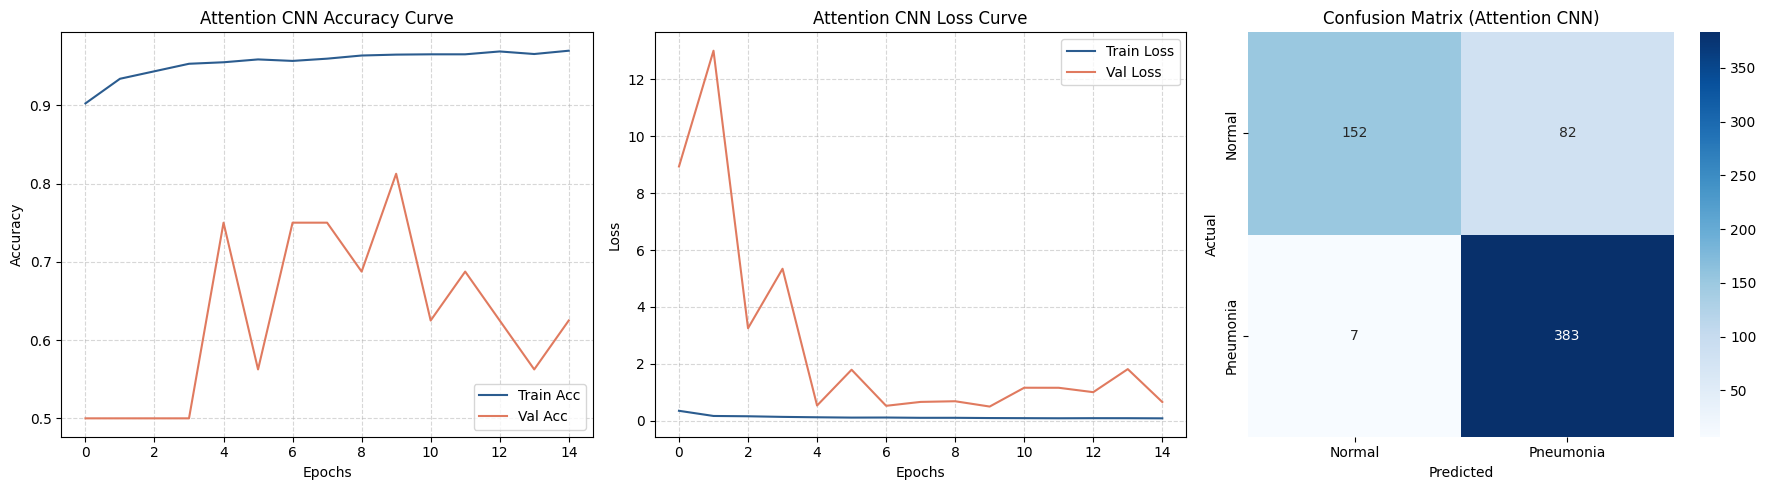

In [6]:
# Visualizing Curves and Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Accuracy Curve
axes[0].plot(history_attention.history['accuracy'], label='Train Acc', color='#2b5c8f')
axes[0].plot(history_attention.history['val_accuracy'], label='Val Acc', color='#e07a5f')
axes[0].set_title('Attention CNN Accuracy Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Loss Curve
axes[1].plot(history_attention.history['loss'], label='Train Loss', color='#2b5c8f')
axes[1].plot(history_attention.history['val_loss'], label='Val Loss', color='#e07a5f')
axes[1].set_title('Attention CNN Loss Curve')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
axes[2].set_title('Confusion Matrix (Attention CNN)')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

BASELINE VS. ATTENTION MODULE PERFORMANCE COMPARISON
                          Model  Accuracy  Precision  Recall  F1-Score
    Baseline Custom CNN (Sub 3)    0.8814     0.8652  0.9410    0.9015
Attention-Augmented CNN (Sub 4)    0.8574     0.8237  0.9821    0.8959


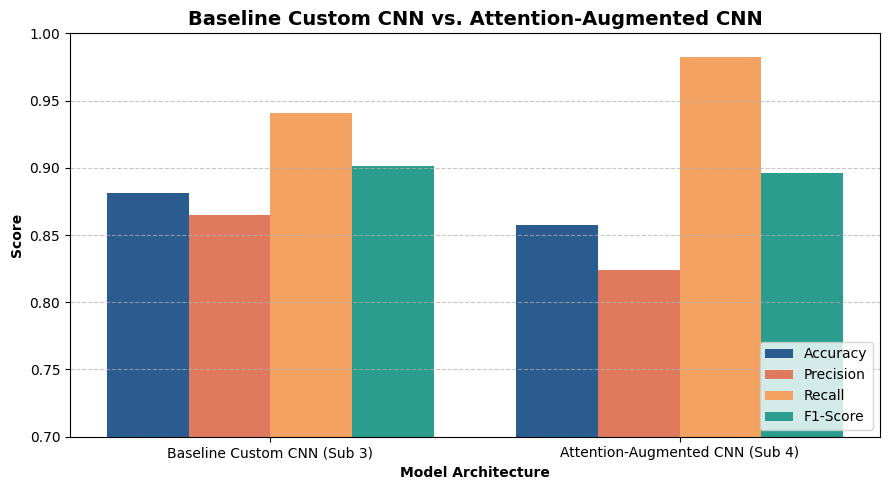

In [7]:
# Direct Comparison Table: Baseline Custom CNN (Submission 3) vs. Attention-Augmented CNN (Submission 4)
# (Note: Replace these placeholder baseline metrics with the exact scores you recorded from running Submission 3)
comparison_data = [
    {"Model": "Baseline Custom CNN (Sub 3)", "Accuracy": 0.8814, "Precision": 0.8652, "Recall": 0.9410, "F1-Score": 0.9015},
    {"Model": "Attention-Augmented CNN (Sub 4)", "Accuracy": round(attn_acc, 4), "Precision": round(attn_prec, 4), "Recall": round(attn_rec, 4), "F1-Score": round(attn_f1, 4)}
]

comparison_df = pd.DataFrame(comparison_data)

print("=" * 80)
print("BASELINE VS. ATTENTION MODULE PERFORMANCE COMPARISON")
print("=" * 80)
print(comparison_df.to_string(index=False))

# Visualization Comparison Bar Chart
plt.figure(figsize=(9, 5))
x = np.arange(len(comparison_df))
width = 0.2

plt.bar(x - 1.5*width, comparison_df['Accuracy'], width, label='Accuracy', color='#2b5c8f')
plt.bar(x - 0.5*width, comparison_df['Precision'], width, label='Precision', color='#e07a5f')
plt.bar(x + 0.5*width, comparison_df['Recall'], width, label='Recall', color='#f4a261')
plt.bar(x + 1.5*width, comparison_df['F1-Score'], width, label='F1-Score', color='#2a9d8f')

plt.xlabel('Model Architecture', fontweight='bold')
plt.ylabel('Score', fontweight='bold')
plt.title('Baseline Custom CNN vs. Attention-Augmented CNN', fontsize=14, fontweight='bold')
plt.xticks(x, comparison_df['Model'])
plt.ylim(0.7, 1.0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()